# AI-assisted JavaScript Development


A practical guide to working with AI as a development partner for vanilla JavaScript. This course covers how to prompt effectively, translate pseudocode into working code, debug with AI assistance, and take full ownership of AI-generated output.


## Table of Contents

- [Module 01: Generating and Understanding JavaScript with AI](#module-01)
- [Module 02: Turning Pseudocode into Working JavaScript Logic](#module-02)
- [Module 03: Debugging JavaScript Faster with AI](#module-03)
- [Module 04: Owning AI-assisted Code](#module-04)


In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))


---

## Module 01: Generating and Understanding JavaScript with AI

_How to use AI as a fast pair programmer while keeping yourself as the developer — covering the AI developer workflow, editor settings, prompt structure, and code comprehension._


### The AI Developer Mindset

> AI is a fast pair programmer. You are the developer.

AI accelerates the mechanical parts of coding but cannot take responsibility for what the code does. That stays with you.


### Division of Labor and Responsibility

**Where AI shines** vs. **What stays yours:**

| Where AI shines | What stays yours |
|---|---|
| Explanations | Reasoning |
| Examples | Understanding the output |
| Boilerplate | Validating code correctness |
| First drafts | |
| Debugging hypotheses | |


### The AI Developer Workflow

A repeating cycle that keeps the human in control at every step:



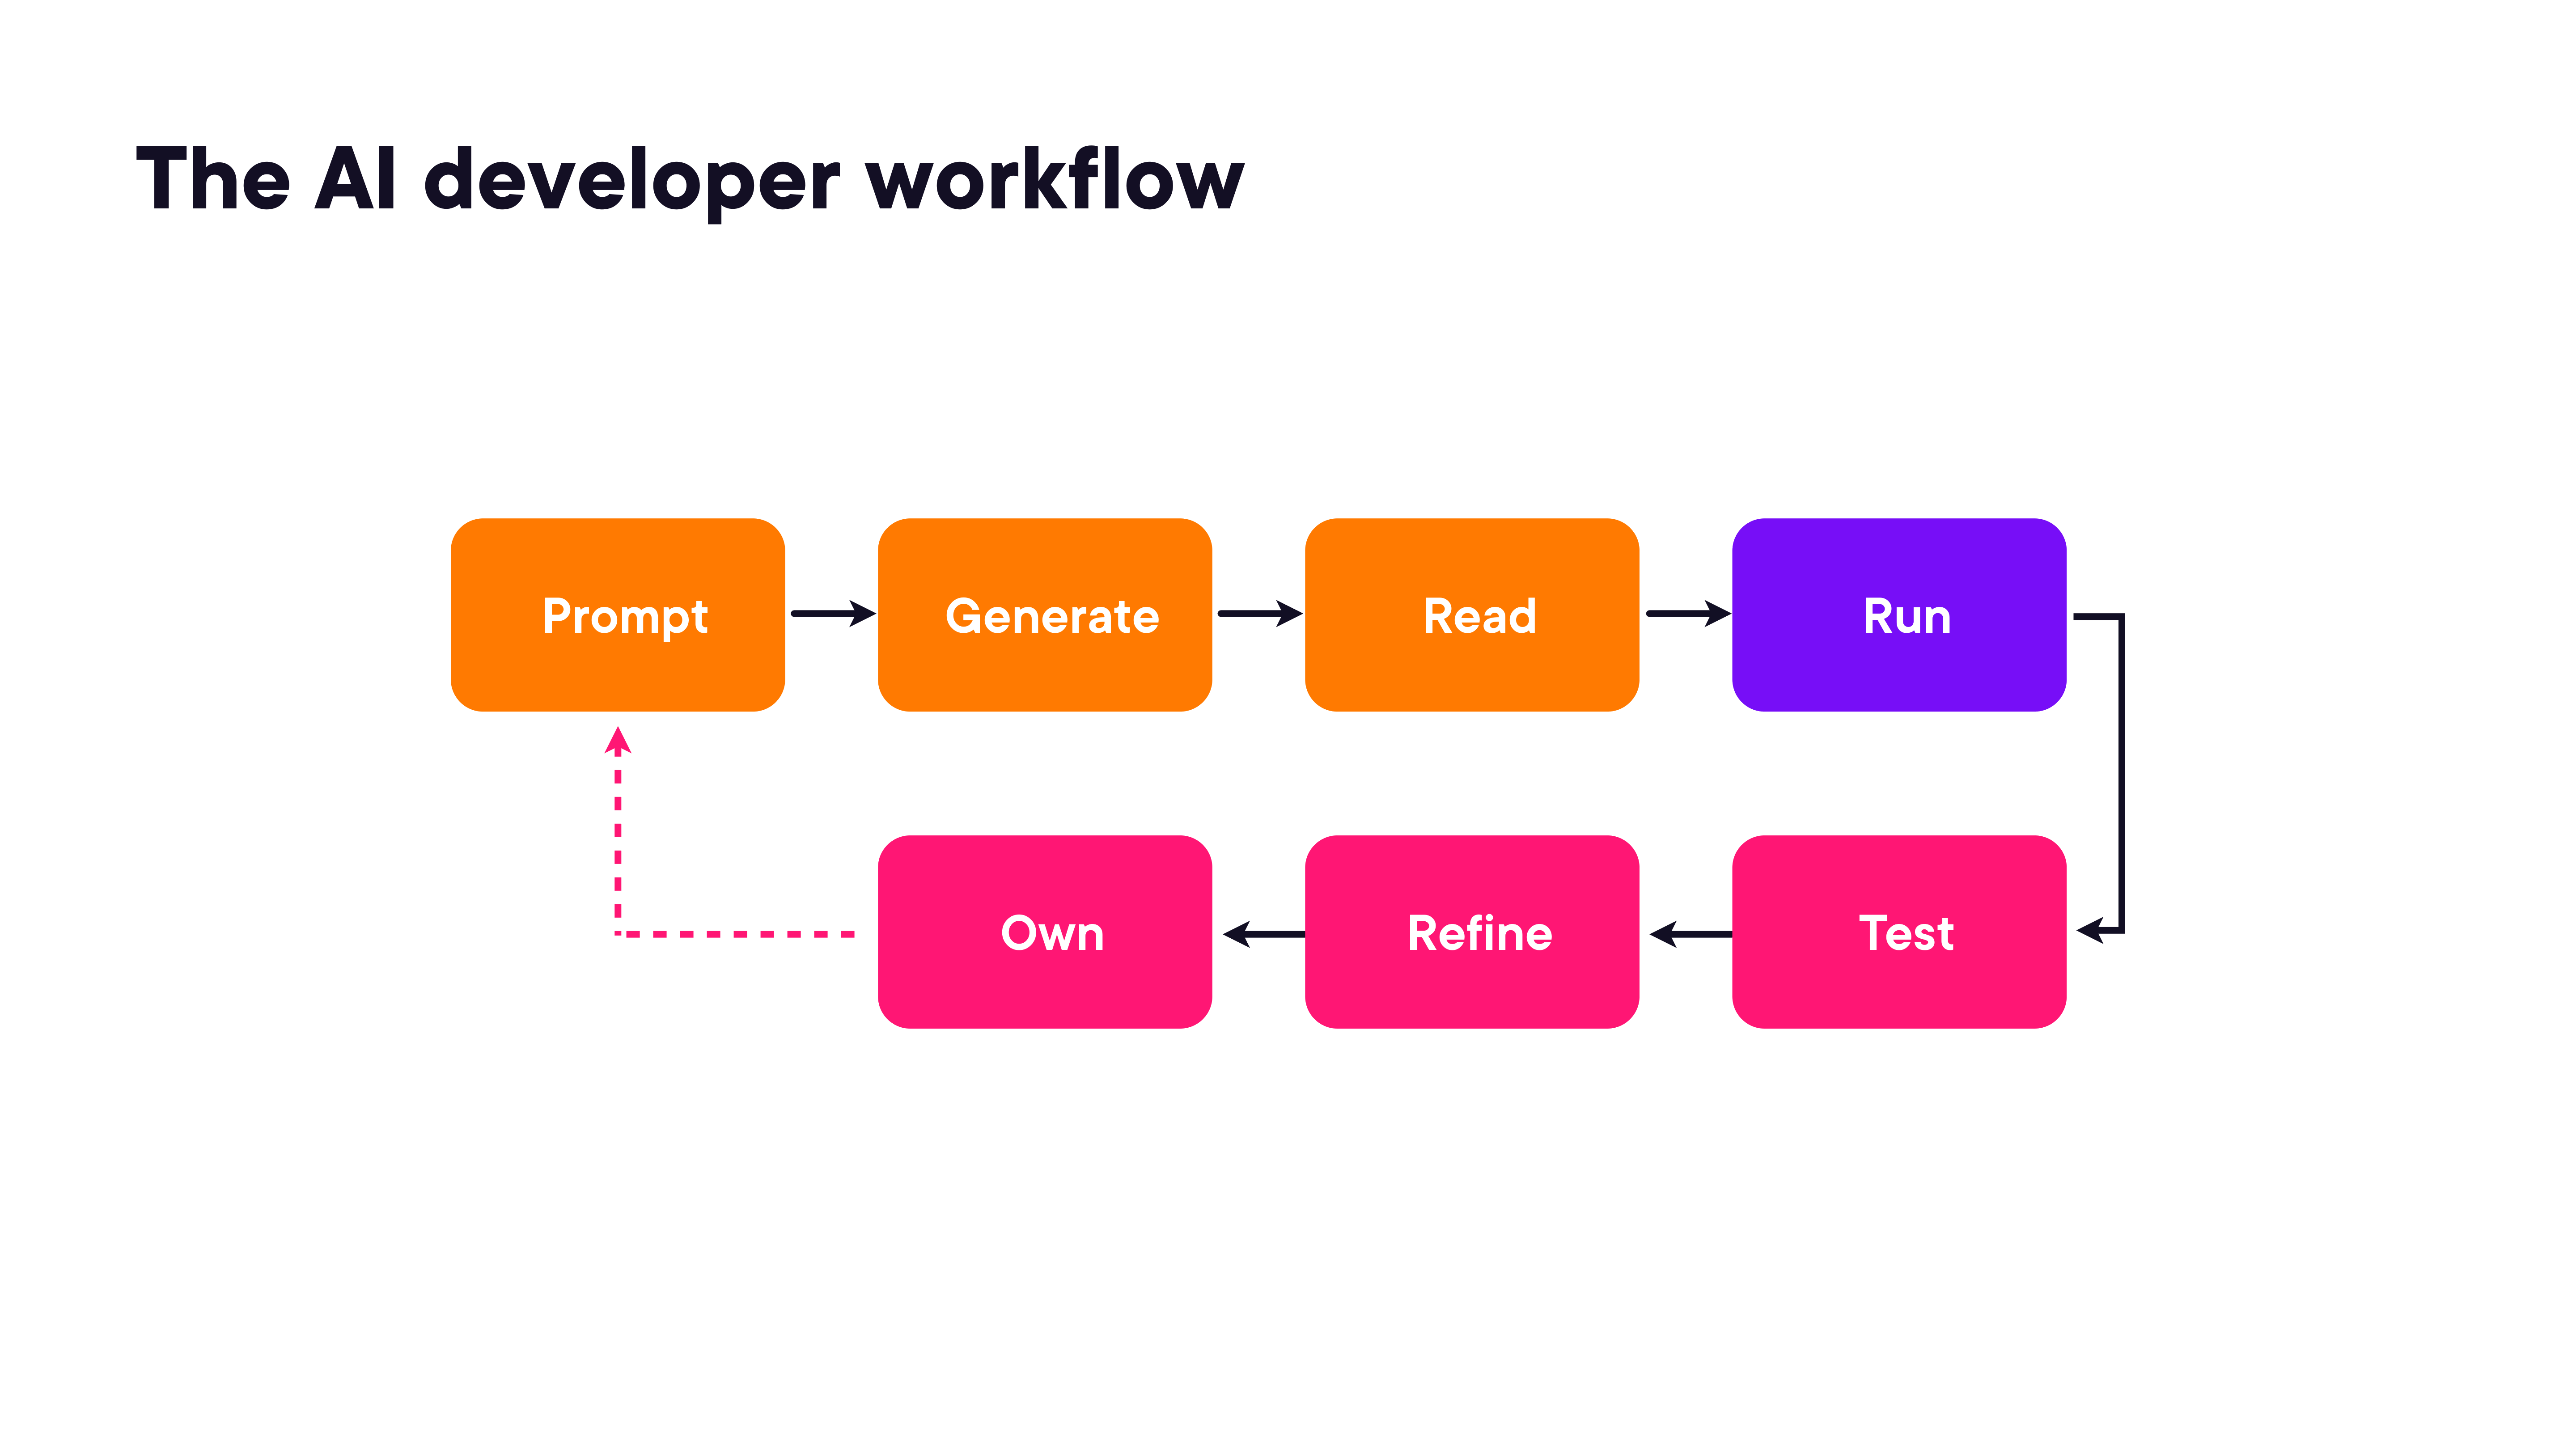

In [2]:
render_diagram(Path('assets/01-ai-developer-workflow.png'))


The cycle: **Prompt → Generate → Read → Test → Refine → Own → Run**

You prompt with intent, read what comes back, test it against the real requirements, refine until it's right, and own the result before shipping it.


### AI Code Editors and Their Settings

#### Common AI Code Editors

- **GitHub Copilot** — inline suggestions and chat inside any editor
- **Cursor** — AI-native editor built on VS Code
- **Claude Code** — terminal-based agentic tool from Anthropic

#### Key Settings to Understand (Across All Tools)

| Setting | What it Controls |
|---|---|
| Which model is answering | Capability and cost of each response |
| How hard it is thinking | Extended reasoning vs. fast completion |
| What context it can see | Files, open tabs, terminal, entire repo |
| How much it can do alone | Inline only vs. autonomous file editing |

This course uses **Claude Code inside VS Code** for all demos.

> Don't memorize interfaces. Know your model, know your reasoning setting, know what context your AI can see. Know how much it can do without asking you first.


### Generating the Project Scaffold

Start by asking AI to create the skeleton: HTML file, CSS file, and an empty `app.js`. Give it the project name and a one-line description of what it does. Review every file it creates before moving on — scaffolding is fast to generate but easy to misunderstand if you skip the read step.


### Asking Clear JavaScript Questions

Vague prompts produce vague answers. Every prompt needs five things:

| Element | What it provides |
|---|---|
| **The goal** | What decision or output you need |
| **The context** | What the code does, what already exists |
| **Any constraints** | Language version, no frameworks, etc. |
| **Expected inputs and outputs** | Concrete examples help |
| **The actual ask** | The specific question or task |


#### Elements of a Specific Prompt

1. **The goal** — what decision or output you need
2. **The context** — what the code does, what already exists
3. **Any constraints** — language version, no frameworks, etc.
4. **Expected inputs and outputs** — concrete examples help
5. **The actual ask** — the specific question or task

#### Example: `const` vs `let` for a task array

```
Goal: Decide how to declare the collection that holds my tasks.
Context: This is a vanilla JavaScript task app. The variable will hold an
array of task objects, and I'll add tasks to it with push() as the user
creates them. This is the line I'm about to write:
  const tasks = [];
Constraints: Modern JavaScript, no frameworks.
Ask: Should this be const or let, and why? Keep it short, with one small
example using a tasks array like mine.
```

The answer: `const` — because `const` prevents reassignment of the variable itself, but the array it points to is still mutable. You can `push()` to it freely. Using `let` would signal to readers that the variable might be reassigned, which is misleading.


### Generating Boilerplate Without Turning Off Your Brain

> This is behavior, the code that decides what happens when somebody clicks a button, and behavior can be quietly, plausibly wrong.

Boilerplate — element selections, event listeners, render loops — is safe to generate. But the logic that decides *what happens* requires your attention. Always read behavior code before accepting it.

#### Example: Generating Task App Behavior

```
I'm building a small vanilla JavaScript task app. The HTML and CSS are
finished, and app.js already selects the elements I need and includes a
createTaskElement(task) helper.

Generate only the JavaScript needed to:
1. Store tasks in an array. Each task has a title and a priority.
2. Add a task when the Add button is clicked, using the text input and
   the priority select.
3. Render all tasks into the #task-list element using createTaskElement.

Constraints:
- No frameworks, no new files.
- Clear, beginner-friendly function names.
- Don't rewrite the code that's already in app.js.
- Leave the filter dropdown alone for now; I'll wire that up later.
- After the code, briefly explain what each function does.
```

Notice the constraints prevent the AI from touching code you didn't ask it to touch — a discipline that keeps generated output reviewable.


### Using AI to Explain Unfamiliar Code

When you encounter a function you don't fully understand, paste it into your AI chat with a one-sentence question: "What does this do and why?"

After reading the explanation:

> Close the chat and explain the function in your own words.

If you can't do that without looking, you haven't understood it yet. Go back, ask a follow-up, and try again. This is how ownership gets built — not from reading, but from being able to explain.


### Demo: Generating JavaScript with AI

A complete task app project demonstrating the scaffold generation and boilerplate prompting techniques from this module.

See [`01-generating-javascript-demos/`](01-generating-javascript-demos/) for the full project.


---

## Module 02: Turning Pseudocode into Working JavaScript Logic

_A three-step technique for producing reliable JavaScript logic: convert requirements to pseudocode, validate the pseudocode, then convert it to code. Includes test setup with Vitest and evaluating multiple AI-generated implementations._


### Feature: Priority Filter

> When the user picks a priority from the filter dropdown, the list shows only the tasks with that priority, and picking All shows everything.

This single feature requirement drives the entire module. Rather than asking AI for JavaScript immediately, the approach is to first reason about the behavior in plain language.


### Why Bounded Requests Work Better

> Small, bounded requests produce dramatically better output than whole-feature asks.

Asking for an entire feature in one prompt forces the AI to make assumptions about structure, naming, and edge cases — many of which won't match your codebase. Breaking the work into stages keeps each AI response small enough to read and validate.


### Step 1: Turn Requirements into Pseudocode

Ask for pseudocode first — no JavaScript yet. This forces both you and the AI to think through the logic before any syntax is involved.

#### Filtering Feature Prompt

```
Here's the next feature for my vanilla JavaScript task app:
When the user picks a priority from the filter dropdown, the list shows
only tasks with that priority. Picking "All" shows every task. A missing
selection should behave like "All". An unknown priority matches nothing.

Write pseudocode for this feature. Do not write any JavaScript yet.
Keep it short, and include the edge cases you think matter.
```

#### Claude Code Response — Filtering Pseudocode (final, after iteration)

```
FUNCTION filterTasksByPriority(tasks, selectedPriority):
    # Bad input shouldn't throw — hand back nothing
    IF tasks is not a list:
        RETURN empty list
    # Treat "no selection" the same as "all"
    IF selectedPriority is missing (null / undefined / "")
       OR selectedPriority equals "all":
        RETURN a copy of tasks
    # Otherwise keep only exact priority matches
    RETURN tasks WHERE task.priority equals selectedPriority

ON dropdown change:
    read selectedPriority from the dropdown
    visible = filterTasksByPriority(allTasks, selectedPriority)
    render(visible)
```

The pseudocode is your specification. Read it carefully before moving on — this is the moment to catch logic errors cheaply.


### Step 2: Turn the Pseudocode into JavaScript

Now hand the pseudocode back to the AI with structural constraints:

#### JavaScript Generation Prompt

```
Turn this pseudocode into JavaScript.
Constraints:
- Create logic.js and export filterTasksByPriority from it as a pure function. No
  DOM access in that file.
- Return a new array. Never modify the tasks array I pass in.
- Only the filtering function for now — don't wire up the dropdown yet, and don't
  change app.js.
```

The constraint "pure function, no DOM access" is the key architectural boundary — logic and presentation stay separate from the start.


### Step 3: Check the Logic with Tests

Before wiring the function to the UI, verify the logic in isolation.

#### Setting Up Vitest

```
Set this project up to run unit tests with Vitest.
Constraints:
- Add package.json and vitest.config.js. Don't touch app.js, logic.js, index.html, or
  styles.css.
- Vitest and jsdom as dev dependencies. Nothing else.
- Use the jsdom test environment — logic.js is where our save-and-load code will
  live, and plain Node has no localStorage.
- Add a "test" script. Nothing else: no linter, no CI config.
- Write the files only — don't run npm install. I'll install once I've read them.
```

#### Creating the Tests

```
Generate Vitest tests for filterTasksByPriority in logic.test.js, based on this
plan: matching priorities are returned in a new array, "all" returns every task, a
missing selection behaves like "all", an unknown priority returns an empty array,
and an empty list returns an empty array. Small sample data, one behavior per test.
```

One behavior per test is non-negotiable. A test that checks three things at once tells you something failed but not what.


### Pair Coding Without Surrendering Control

When AI offers multiple implementations, evaluate them yourself against the pseudocode spec. Three options the AI might produce:

#### Option A — Explicit Set for "show all" values

```javascript
// Selections that mean "don't filter at all".
const SHOW_ALL = new Set([null, undefined, "", "all"]);

export function filterTasksByPriority(tasks, selectedPriority) {
  if (!Array.isArray(tasks)) {
    return [];
  }
  if (SHOW_ALL.has(selectedPriority)) {
    return tasks.slice();
  }
  return tasks.filter((task) => task.priority === selectedPriority);
}
```

#### Option B — Normalize missing to "all" with ternary

```javascript
export function filterTasksByPriority(tasks, selectedPriority) {
  if (!Array.isArray(tasks)) {
    return [];
  }
  // A missing selection is the same as asking for everything.
  const priority =
    selectedPriority == null || selectedPriority === "" ? "all" : selectedPriority;
  return priority === "all" ? tasks.slice() : tasks.filter((task) => task.priority === priority);
}
```

#### Option C — Single boolean flag

```javascript
export function filterTasksByPriority(tasks, selectedPriority) {
  if (!Array.isArray(tasks)) {
    return [];
  }
  // A missing selection behaves like "all".
  const showAll =
    selectedPriority == null || selectedPriority === "" || selectedPriority === "all";
  return tasks.filter((task) => showAll || task.priority === selectedPriority);
}
```

All three satisfy the pseudocode spec. Option A is the most explicit and easiest to extend. Option C is the most compact. The choice is yours — the AI can produce options, but only you know which style fits this codebase.


### Demo: Pseudocode to JavaScript

The task app at the end of this module, with `logic.js`, `logic.test.js`, and `vitest.config.js` in place. Includes both `before` (just the app) and `after` (with filtering and tests) states.

See [`02-pseudocode-to-javascript-demos/`](02-pseudocode-to-javascript-demos/) for the full project.


---

## Module 03: Debugging JavaScript Faster with AI

_A systematic debugging loop using AI as a hypothesis generator. Covers runtime errors, logic errors, persistence bugs, regression testing, and turning bugs into written lessons._


### The Core Principle

> AI generates hypotheses. You run experiments.

AI cannot run your code. It cannot inspect your browser's memory. It can only reason from the evidence you give it. Your job is to supply good evidence and run the smallest possible experiment to confirm or rule out each hypothesis.


### The Debug Evidence Pack

Structure every debugging prompt around the same seven fields:

**Debug evidence pack**

1. **Expected behavior** — what should happen
2. **Actual behavior** — what actually happens
3. **Exact error** — copy the full error message and the line it points to
4. **Relevant code** — the smallest snippet that shows the problem
5. **Input data** — exactly what was typed or passed in
6. **What changed** — any recent edits, refactors, or deploys
7. **What I tried** — experiments already run and their results

Supplying all seven fields upfront gets you useful hypotheses on the first response, not a back-and-forth asking for more context.


### Fixing a Runtime Error

#### Debugging Prompt — Null element

```
I'm debugging a runtime error in my vanilla JS task app.
Expected: clicking Add creates a task and renders it in the list.
Actual: nothing renders.
Exact error: Uncaught TypeError: Cannot read properties of null (reading 'value'),
thrown from `const title = taskInput.value.trim();` inside addTask.
Input: typed "Ship report", priority High.
Recently changed: a teammate refactored app.js and added persistence.
Already tried: confirmed the error points at the line reading taskInput, so
taskInput is null.
Relevant code is in app.js — the element selections are at the top.
Give me 2–3 likely causes and the smallest next experiment for each.
```

Asking for "the smallest next experiment" is important — it keeps you in control of what gets tested and prevents AI from suggesting a sweeping rewrite instead of a targeted check.

The root cause here: the element `id` was changed during the refactor (e.g. `task-input` renamed to `taskInput`), so `document.getElementById('task-input')` returns null.


### Debugging a Logic Error

Logic errors are harder because no exception is thrown — the code runs but produces wrong results.

#### Debugging Prompt — Mutating filter

```
Why is this loop failing?
Expected: with selectedPriority "high", only high-priority tasks are returned.
Actual: every task is returned, and afterward every task's priority has changed to
"high".
Sample input:
[
  { title: "Ship report", priority: "high" },
  { title: "Water plants", priority: "low" }
]
Determine the root cause. Only report.
```

"Only report" prevents the AI from generating a fix before you've understood the problem. The root cause: `task.priority = selectedPriority` (assignment) instead of `task.priority === selectedPriority` (comparison) in the filter condition.

After diagnosis, confirm your understanding against the original pseudocode spec before accepting any proposed fix.


### Getting a Second Opinion from a Fresh AI Session

When a bug resists diagnosis, open a new AI session with no prior context — this eliminates anchoring bias where the AI keeps revisiting the same wrong hypothesis.

#### Debugging Prompt — Persistence bug

```
Expected: tasks persist across a page refresh.
Actual: after refresh the list is empty. No console errors.
Evidence: localStorage has key "task-prioritizer.tasks" with a valid JSON array
string. Saving works; loading doesn't.
Give me 2–3 likely causes and the smallest next experiment.
```

The root cause: `localStorage.getItem(...)` returns a JSON string, but the code uses it directly as an array instead of calling `JSON.parse()` on it.

> Evidence in, hypotheses out. Experiments decide.


### Turning Each Bug into a Test

Every fixed bug is a regression test you now know you need. Write it before moving on.

#### Testing Prompt — Regression for the mutating filter bug

```
Add a Vitest regression test to logic.test.js: filtering by "high" must return only
matching tasks AND must not modify any task in the input array. Name it so a future
reader knows it guards against an assignment typo in the filter condition.
```

The test name becomes living documentation of the bug's history.

> Debugging and testing aren't separate skills; each bug you fix is a test you now know you need.


### Capturing Lessons Learned

After fixing a batch of bugs, ask AI to help write a `lessons-learned.md`:

```
For the three bugs we fixed in this session — the typo'd element id, the = instead
of === in the filter, and the missing JSON.parse — write a lessons-learned.md in the
project root.
One entry per bug: the root cause in a sentence, and how to catch it earlier next
time. Then a Prompts section at the bottom holding the evidence pack template we
used all session.
Keep it short enough that I'll actually reread it.
```

The constraint "short enough that I'll actually reread it" is doing real work — verbose lesson docs get skipped.


### The AI Debugging Loop

**AI debugging loop** — follow this sequence for every bug:

1. **Evidence first** — collect all seven fields before asking AI anything
2. **AI generates hypotheses** — prompt with the full evidence pack
3. **Get a second opinion from AI when needed** — fresh session, no anchoring
4. **Smallest experiment** — confirm or rule out one hypothesis at a time
5. **Smallest fix** — change only what the diagnosis requires
6. **Verify against the plan** — check the fix against your pseudocode spec
7. **Regression test** — add a test that would have caught this bug
8. **Get a written lesson** — document root cause and how to catch it earlier


### Demo: Debugging with AI

The task app with all three bugs present in `before/` and fixed in `after/`, plus `lessons-learned.md` generated during the session.

See [`03-debugging-with-ai-demos/`](03-debugging-with-ai-demos/) for the full project.


---

## Module 04: Owning AI-assisted Code

_How to review, override, and iterate on AI-generated features — including agentic tools, the autonomy spectrum, and maintaining structural integrity across the full project._


### Where AI Is Faster

| The AI fast lane | The slow lane (human must drive) |
|---|---|
| Boilerplate | Requirements |
| Syntax recall | Correctness |
| Explanations | Security-sensitive code |
| First drafts | Dependencies |
| Test scaffolds | Architecture |
| Error triage | |


### The AI Autonomy Spectrum



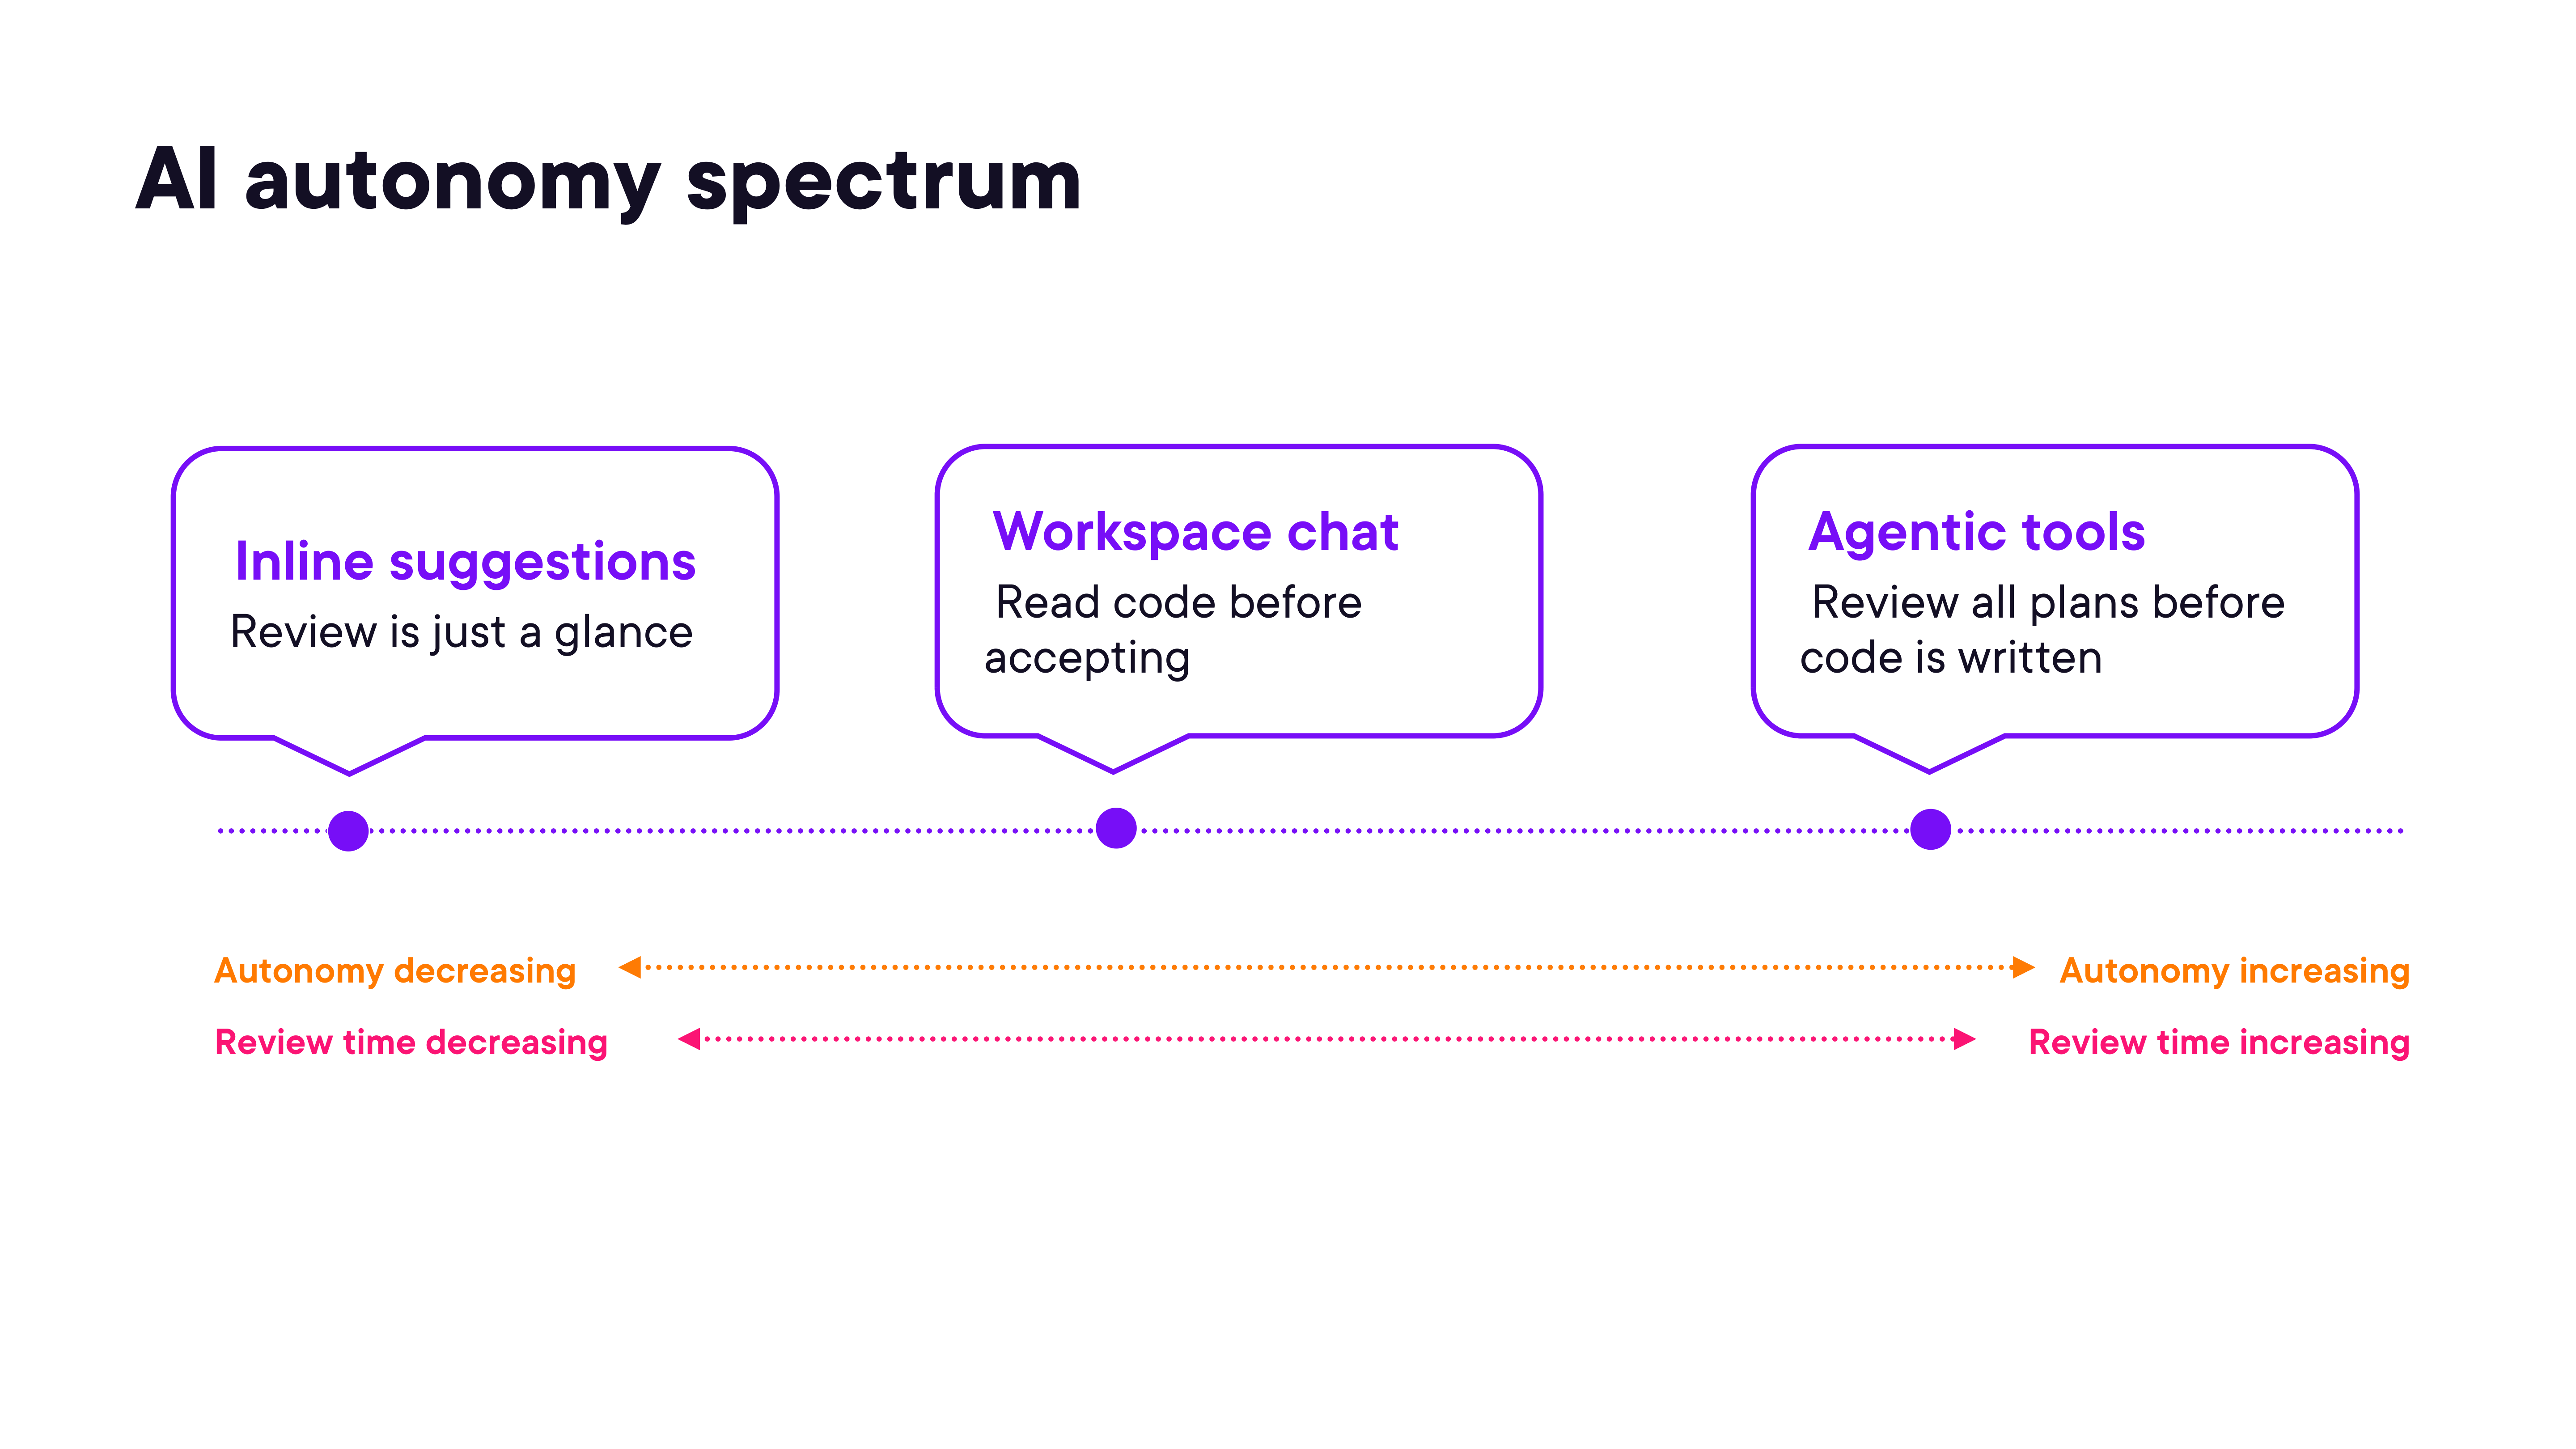

In [3]:
render_diagram(Path('assets/02-ai-autonomy-spectrum.png'))


| Mode | Review Required |
|---|---|
| Inline suggestions | A glance — accept or decline |
| Workspace chat | Read the code before accepting |
| Agentic tools | Review all plans before code is written |

More autonomy = more review time required, not less. At the agentic level, you review plans the way you review pull requests — before the code lands.


### Reviewing an Agent's Work Like a Pull Request

When using an agentic tool for a multi-file feature, treat every generated diff as a PR. Read each changed file. Verify behavior against the requirements. Check that the AI respected structural boundaries.

#### Task Completion Feature Prompt

```
Add the ability to mark a task as complete.
Requirements:
- Give each task a stable id when it's created.
- Each task in the list gets a checkbox that toggles completion.
- Completed tasks get a "task-completed" class, and add a style for it in
  styles.css.
- Completed state persists with the rest of the task data.
- Keep the existing structure: pure logic in logic.js, only storage.js touches
  localStorage, DOM work in app.js.
- Keep existing function names. No new dependencies. Don't change index.html.
```

The structural constraints in the prompt are your architecture spec. After the agent runs, verify each constraint was honored — don't assume.


### Overruling the AI

Asking for a plan before code gives you a review checkpoint before anything is written:

#### Task Sorting Prompt

```
Show tasks in the list with the highest priority first.
Give me your plan first — don't change any files yet.
```

When the AI proposes sorting in `app.js` (the rendering layer) but the correct place is `logic.js` (the pure logic layer), you reject the plan and specify where the sort function belongs. The AI doesn't know your architecture — you do.

> AI output is a proposal, not a verdict.


### Iterating to a Finished Feature

Complex features can be broken into plan → pseudocode → code → tests — and each step can involve AI. The key is sequencing: pseudocode before code, plan before writing.

#### Task Summary Feature Prompt

```
Feature: a summary line above the task list.
Behavior:
- Normally: "3 of 5 tasks remaining · 2 high priority" — remaining means not
  completed; the high count is remaining tasks only.
- No tasks at all: "No tasks yet — add your first one."
- Everything complete: "All tasks complete."
Plan:
1. Add a <p id="summary"> above the task list in index.html.
2. Pure function summarizeTasks(tasks) in logic.js returning { total, remaining, high }.
3. app.js formats the message and renders it into #summary.
4. Vitest tests: normal case, empty list, all complete, no high tasks.
Write pseudocode for summarizeTasks first. No JavaScript yet.
```

#### Claude Code Response — Pseudocode

```
FUNCTION summarizeTasks(tasks):
    # Same bad-input guard the other logic functions use, so a caller
    # that hands over a non-array gets zeroed counts instead of a crash.
    IF tasks is not an array:
        RETURN { total: 0, remaining: 0, high: 0 }
    SET total     TO count of tasks
    SET remaining TO 0
    SET high      TO 0
    FOR EACH task IN tasks:
        # "Completed" is explicitly true — anything else (missing field,
        # undefined, a stray string) counts as not done.
        IF task.completed is exactly true:
            SKIP to next task
        INCREMENT remaining
        # Reached only for remaining tasks, so `high` is a subset of
        # `remaining` and can never exceed it.
        IF task.priority is exactly "high":
            INCREMENT high
    RETURN { total, remaining, high }
```

Verify the pseudocode handles all four test cases before writing JavaScript.

> Good structure is a decision, not a default.


### Your AI-assisted Workflow Going Forward

The same workflow from Module 01 applies to every feature, at every scale:



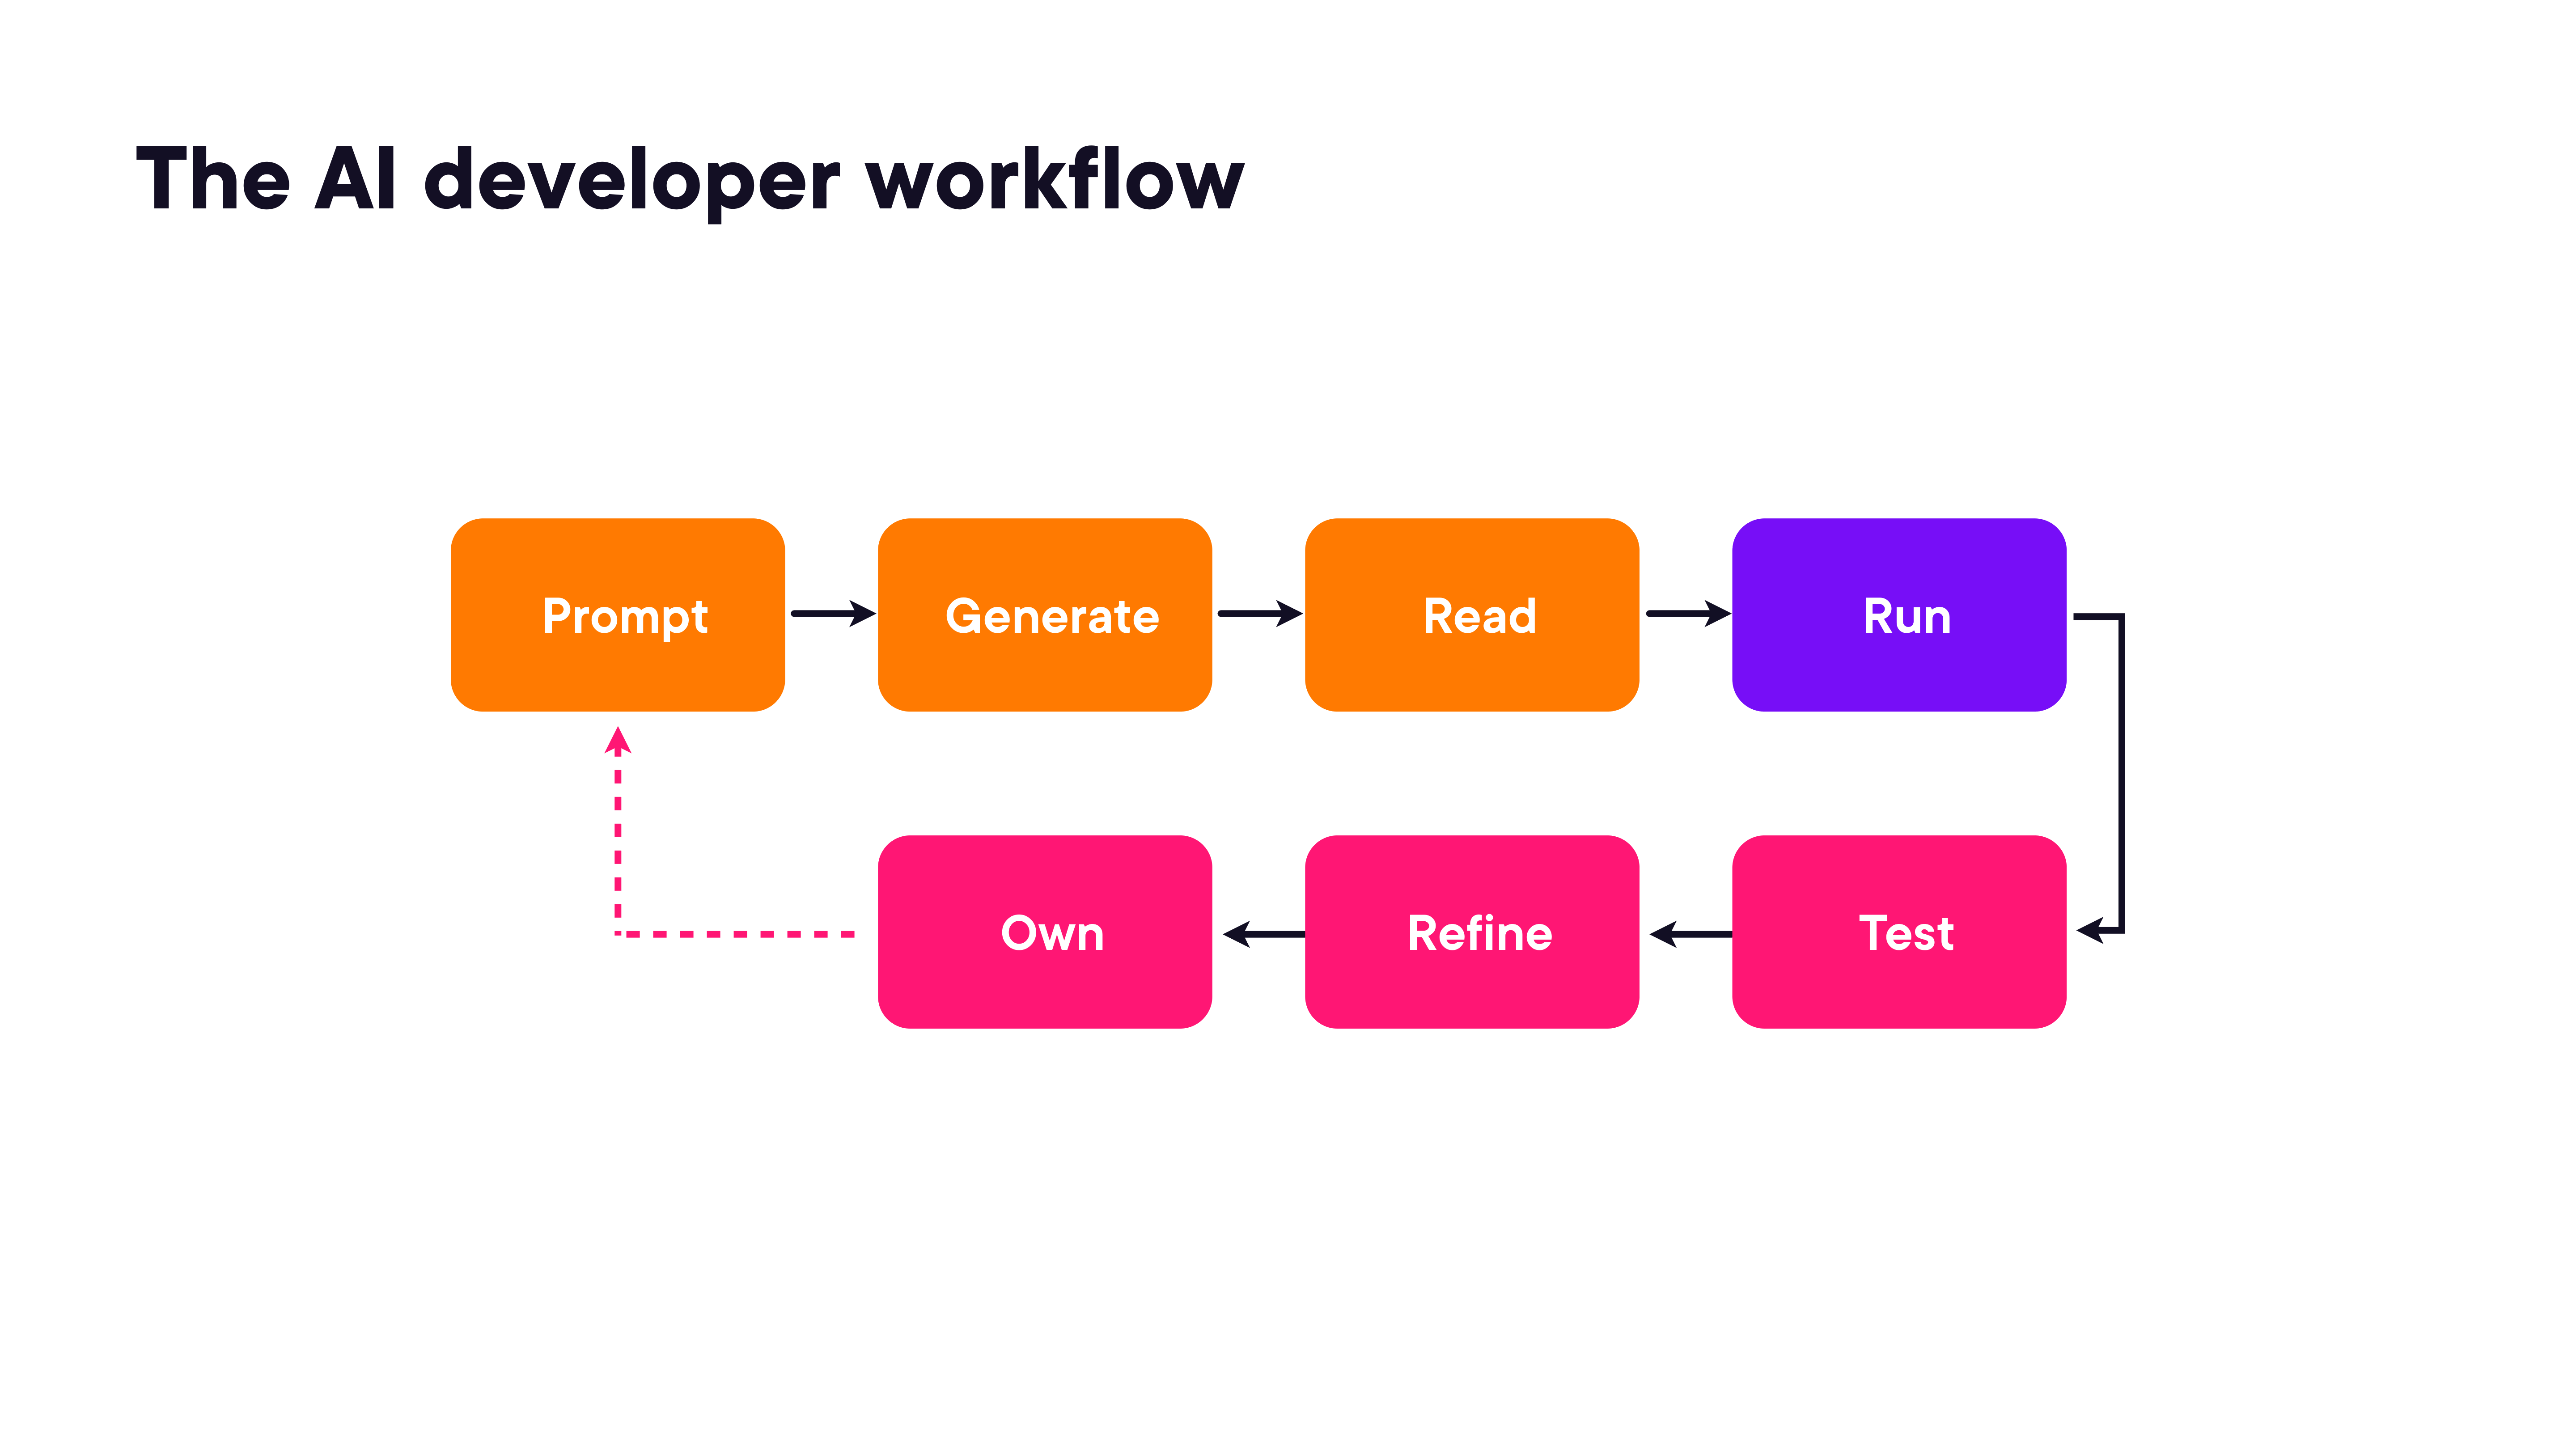

In [4]:
render_diagram(Path('assets/03-ai-developer-workflow-final.png'))


**Prompt → Generate → Read → Test → Refine → Own → Run**

The model changes. The editor changes. The project grows. The workflow stays the same because it's not about the tools — it's about maintaining the human in the loop at every decision point.

What scales:
- The evidence pack template works for any debugging conversation
- The five-part prompt structure works for any feature request
- The pseudocode-first approach works for any non-trivial logic
- Plan-first before agentic runs works at any scale of feature


### Demo: Owning AI-assisted Code

The complete task app with task completion, priority sorting, and task summary — built with the full agentic review workflow. Includes `CLAUDE.md` with project architecture instructions, `lessons-learned.md`, and both `before`/`after` states.

See [`04-owning-ai-code-demos/`](04-owning-ai-code-demos/) for the full project.
